# PreTest 05: เอกสารสรุป Machine Learning (Cheat Sheet) สำหรับการสอบ

> สรุปทุกอย่างจาก PreTest 01–04 ไว้ที่เดียว — **สามารถคัดลอก Template ไปใช้โดยเปลี่ยนเฉพาะชื่อคอลัมน์**
> โค้ดทุก Template **รันได้จริง** (ทดสอบด้วย dataset ตัวอย่างของ sklearn ที่ไม่ต้องดาวน์โหลด)

## สารบัญ
1. เลือกประเภทปัญหา
2. Workflow มาตรฐาน 10 ขั้น
3. Snippet: สำรวจ & ทำความสะอาด
4. Snippet: EDA / Visualization
5. Template: Classification (Pipeline)
6. Template: Regression (Pipeline)
7. Template: Clustering
8. Tuning: GridSearchCV / RandomizedSearchCV
9. ตารางเลือก Metric
10. ตารางเลือกโมเดล (ต้อง Scale หรือไม่ จุดเด่น/จุดด้อย)
11. ข้อผิดพลาดที่พบบ่อย + Error ยอดฮิต
12. Template การเขียนสรุปผล

---
## 1. เลือกประเภทปัญหา
```
มีคอลัมน์คำตอบ (Target) หรือไม่
├── ไม่มี → Unsupervised
│          ├── หากลุ่ม → Clustering (K-Means, Hierarchical, DBSCAN)       [PreTest 04]
│          └── ลดมิติ/วาดกราฟ → PCA
└── มี  → Target เป็นอะไร?
           ├── ตัวเลขต่อเนื่อง (ราคา, จำนวน)  → Regression                 [PreTest 02]
           └── หมวดหมู่
                ├── 2 คลาส  → Binary Classification                       [PreTest 01]
                └── 3+ คลาส → Multiclass Classification                   [PreTest 03]
```
> **ข้อควรระวัง:** Target เป็นตัวเลขแต่มีไม่กี่ค่า (0/1, 1–5 ดาว) → มักเป็น **Classification**

## 2. Workflow มาตรฐาน 10 ขั้น
| ขั้น | ทำอะไร | คำสั่งหลัก |
|---|---|---|
| 1 | กำหนดโจทย์ + Metric | — |
| 2 | โหลดข้อมูล | `pd.read_csv()` |
| 3 | สำรวจ | `.shape`, `.head()`, `.info()`, `.describe()`, `.value_counts()` |
| 4 | Cleaning | `dropna(subset=[target])`, `drop_duplicates()`, `replace('?', np.nan)`, `pd.to_datetime()` |
| 5 | EDA | `countplot`, `histplot`, `boxplot`, `scatterplot`, `pairplot`, `heatmap(corr)` |
| 6 | Split | `train_test_split(..., stratify=y)` |
| 7 | Preprocess | `Pipeline` + `ColumnTransformer` (Imputer → Scaler / OneHot) |
| 8 | เทรน 2–3 โมเดล | `pipe.fit(X_train, y_train)` |
| 9 | Tuning + Evaluate | `GridSearchCV` / `RandomizedSearchCV`, metrics บน Test |
| 10 | เปรียบเทียบ + สรุป | ตาราง metrics + เหตุผลการเลือก |

---
## 3. Snippet: สำรวจ & ทำความสะอาด
```python
df.shape; df.head(); df.info(); df.describe()
df.isnull().sum().sort_values(ascending=False)          # ค่าหายต่อคอลัมน์
(df.isnull().mean() * 100).round(1)                     # % ค่าหาย
df.duplicated().sum(); df = df.drop_duplicates()        # ข้อมูลซ้ำ
df[col].value_counts(dropna=False)                      # หาค่าแปลก เช่น '.', '?', 'unknown'
df[col] = df[col].replace(['.', '?'], np.nan)           # แปลงค่าแปลกเป็น NaN
df = df.dropna(subset=['target'])                       # Target หาย → ลบแถว (ห้ามเติม)
df = df.drop(columns=['id'])                            # ลบคอลัมน์ ID
df['date'] = pd.to_datetime(df['date']); df['month'] = df['date'].dt.month   # แยกวันที่
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(exclude='number').columns.tolist()

# Outlier ด้วย IQR
q1, q3 = df[col].quantile([0.25, 0.75]); iqr = q3 - q1
outliers = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
df[col] = df[col].clip(upper=q3 + 1.5 * iqr)            # ตัดเพดาน (ใช้ค่าจาก Train)
```

## 4. Snippet: EDA / Visualization
| ต้องการดู | กราฟ |
|---|---|
| สัดส่วน Target / หมวดหมู่ | `sns.countplot(x=col, data=df)` |
| การกระจายตัวเลข | `sns.histplot(df[col], kde=True)` |
| Outlier | `sns.boxplot(y=df[col])` |
| ตัวเลข vs Target หมวดหมู่ | `sns.boxplot(x='target', y=col, data=df)` |
| ตัวเลข vs ตัวเลข | `sns.scatterplot(x=a, y=b, hue='target', data=df)` |
| หมวดหมู่ vs หมวดหมู่ | `pd.crosstab(df[a], df[b], normalize='index')` |
| ทุกคู่พร้อมกัน | `sns.pairplot(df, hue='target')` |
| Correlation | `sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')` |

---
## 5. Template: Classification

In [1]:
# ===== TEMPLATE: CLASSIFICATION =====
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix)

# --- (ตัวอย่าง) โหลดข้อมูล: ในข้อสอบเปลี่ยนเป็น df = pd.read_csv('...') ---
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
df = data.frame.rename(columns={'target': 'target'})
TARGET = 'target'

X = df.drop(columns=TARGET)
y = df[TARGET]
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN':                 KNeighborsClassifier(n_neighbors=5),
    'Random Forest':       RandomForestClassifier(n_estimators=200, random_state=42),
}

print(f"Null accuracy (ทายคลาสที่มากที่สุดทุกครั้ง) = {y_test.value_counts(normalize=True).max():.3f}")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
binary = y.nunique() == 2
rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    cv = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1_macro')
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    row = {'Model': name, 'CV F1 (macro)': cv.mean(),
           'Train Acc': pipe.score(X_train, y_train), 'Test Acc': accuracy_score(y_test, pred),
           'Precision': precision_score(y_test, pred, average='binary' if binary else 'macro'),
           'Recall':    recall_score(y_test, pred, average='binary' if binary else 'macro'),
           'F1':        f1_score(y_test, pred, average='binary' if binary else 'macro')}
    if binary:
        row['ROC-AUC'] = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    rows.append(row)

pd.DataFrame(rows).set_index('Model').round(3)

Null accuracy (ทายคลาสที่มากที่สุดทุกครั้ง) = 0.632


,CV F1 (macro),Train Acc,Test Acc,Precision,Recall,F1,ROC-AUC
Model,,,,,,,
Logistic Regression,0.976,0.989,0.982,0.986,0.986,0.986,0.995
KNN,0.960,0.974,0.956,0.959,0.972,0.966,0.979
Random Forest,0.960,1.000,0.956,0.959,0.972,0.966,0.993


In [2]:
# รายละเอียดของโมเดลที่เลือก
best = Pipeline([('prep', preprocessor), ('model', RandomForestClassifier(n_estimators=200, random_state=42))]).fit(X_train, y_train)
print(confusion_matrix(y_test, best.predict(X_test)))      # แถว = จริง, คอลัมน์ = ทำนาย
print(classification_report(y_test, best.predict(X_test)))

[[39  3]
 [ 2 70]]
              precision    recall  f1-score   support

           0       0.95      0.93      0.94        42
           1       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



---
## 6. Template: Regression

In [3]:
# ===== TEMPLATE: REGRESSION =====
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- (ตัวอย่าง) โหลดข้อมูล ---
from sklearn.datasets import load_diabetes
df = load_diabetes(as_frame=True).frame
TARGET = 'target'

X = df.drop(columns=TARGET); y = df[TARGET]
num_cols = X.select_dtypes(include='number').columns.tolist()
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)   # ไม่ต้อง stratify

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first'))]), cat_cols),
])

models = {
    'Linear Regression': LinearRegression(),
    'Ridge':             Ridge(alpha=1.0),
    'Decision Tree':     DecisionTreeRegressor(max_depth=4, random_state=42),
    'Random Forest':     RandomForestRegressor(n_estimators=200, random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    cv = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='r2')
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({'Model': name, 'CV R²': cv.mean(), 'Train R²': pipe.score(X_train, y_train),
                 'Test R²': r2_score(y_test, pred), 'MAE': mean_absolute_error(y_test, pred),
                 'RMSE': np.sqrt(mean_squared_error(y_test, pred))})
print(f"Baseline MAE (ทายค่าเฉลี่ยทุกครั้ง) = {mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())):.2f}")
pd.DataFrame(rows).set_index('Model').round(3)

Baseline MAE (ทายค่าเฉลี่ยทุกครั้ง) = 64.01


,CV R²,Train R²,Test R²,MAE,RMSE
Model,,,,,
Linear Regression,0.480,0.528,0.453,42.794,53.853
Ridge,0.481,0.528,0.454,42.812,53.777
Decision Tree,0.221,0.585,0.326,47.045,59.741
Random Forest,0.409,0.925,0.437,44.415,54.594


> **หมายเหตุ:** ถ้าแปลง Target ด้วย `np.log()` ต้อง **แปลงกลับด้วย `np.exp()` ก่อนรายงาน MAE/RMSE/R²** (บทเรียนจาก PreTest 02)

---
## 7. Template: Clustering

k ที่ Silhouette สูงสุด: 4
              Clusters  Noise  Silhouette
Method                                   
K-Means              4      0       0.797
Hierarchical         4      0       0.797
DBSCAN               3      1       0.745


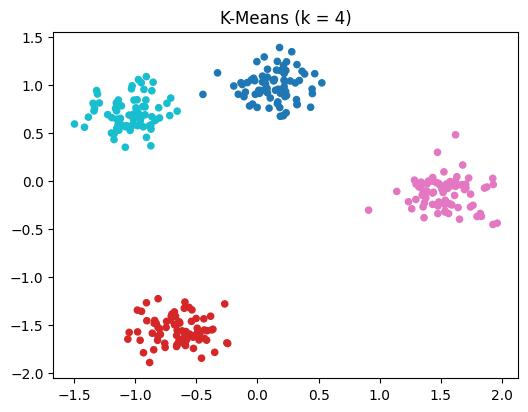

,Inertia,Silhouette,Davies-Bouldin
k,,,
2,315.493,0.558,0.577
3,71.688,0.744,0.370
4,17.466,0.797,0.281
5,15.639,0.674,0.593
6,13.852,0.551,0.824
7,12.182,0.441,0.980
8,10.840,0.338,1.115
9,9.862,0.348,1.012
10,8.832,0.366,0.949


In [4]:
# ===== TEMPLATE: CLUSTERING =====
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA
from sklearn.datasets import make_blobs

# --- (ตัวอย่าง) ข้อมูล: ในข้อสอบ df = pd.read_csv('...'); X_raw = df[['col1', 'col2', ...]] ---
X_raw, _ = make_blobs(n_samples=300, centers=4, cluster_std=1.0, random_state=42)

X = StandardScaler().fit_transform(X_raw)          # ต้อง Scale เสมอ

# 1) เลือก k
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append({'k': k, 'Inertia': km.inertia_, 'Silhouette': silhouette_score(X, km.labels_),
                 'Davies-Bouldin': davies_bouldin_score(X, km.labels_)})
k_table = pd.DataFrame(rows).set_index('k').round(3)
best_k = k_table['Silhouette'].idxmax()
print("k ที่ Silhouette สูงสุด:", best_k)

# 2) เทรน 3 วิธี
labels = {
    'K-Means':      KMeans(n_clusters=best_k, n_init=10, random_state=42).fit_predict(X),
    'Hierarchical': AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X),
    'DBSCAN':       DBSCAN(eps=0.3, min_samples=5).fit_predict(X),      # ปรับ eps จาก k-distance plot
}
summary = []
for name, lab in labels.items():
    m = lab != -1
    summary.append({'Method': name, 'Clusters': len(set(lab[m])), 'Noise': int((~m).sum()),
                    'Silhouette': silhouette_score(X[m], lab[m])})
print(pd.DataFrame(summary).set_index('Method').round(3))

# 3) วาดกราฟ (ถ้าเกิน 2 มิติใช้ PCA)
X_2d = PCA(n_components=2).fit_transform(X) if X.shape[1] > 2 else X
plt.figure(figsize=(6, 4.5)); plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels['K-Means'], cmap='tab10', s=20)
plt.title(f'K-Means (k = {best_k})'); plt.show()
k_table

> **หมายเหตุ:** ขั้นตอนสุดท้ายที่ต้องทำ: `df.groupby('cluster')[cols].mean()` → ตั้งชื่อ Persona ให้แต่ละกลุ่ม → ข้อเสนอแนะ

---
## 8. Tuning: GridSearchCV / RandomizedSearchCV

In [5]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint, loguniform

# --- ใช้ข้อมูล Classification จากข้อ 5 ---
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
pipe = Pipeline([('scaler', StandardScaler()), ('model', RandomForestClassifier(random_state=42))])

# GridSearchCV: ลองทุกค่า (พารามิเตอร์น้อย)
grid = GridSearchCV(pipe, {'model__n_estimators': [100, 200], 'model__max_depth': [None, 5, 10]},
                    cv=5, scoring='f1', n_jobs=-1).fit(X_train, y_train)
print("Grid   best:", grid.best_params_, round(grid.best_score_, 4))

# RandomizedSearchCV: สุ่มลอง n_iter ครั้ง (พารามิเตอร์เยอะ / ช่วงกว้าง)
rand = RandomizedSearchCV(pipe, {'model__n_estimators': randint(50, 400), 'model__max_depth': randint(2, 20),
                                 'model__min_samples_leaf': randint(1, 10)},
                          n_iter=15, cv=5, scoring='f1', random_state=42, n_jobs=-1).fit(X_train, y_train)
print("Random best:", rand.best_params_, round(rand.best_score_, 4))
print("Test F1 ของโมเดลที่ดีที่สุด:", round(f1_score(y_test, rand.best_estimator_.predict(X_test)), 4))

Grid   best: {'model__max_depth': None, 'model__n_estimators': 200} 0.9667


Random best: {'model__max_depth': 8, 'model__min_samples_leaf': 4, 'model__n_estimators': 398} 0.9668
Test F1 ของโมเดลที่ดีที่สุด: 0.9655


| พารามิเตอร์ที่จูนบ่อย | โมเดล | ช่วงที่นิยม |
|---|---|---|
| `C` | LogisticRegression, SVC | 0.01 – 100 (log scale) |
| `n_neighbors` | KNN | 3 – 25 (เลขคี่) |
| `max_depth`, `min_samples_leaf` | Decision Tree, Random Forest | 3 – 20, 1 – 50 |
| `n_estimators` | Random Forest, Gradient Boosting | 100 – 500 |
| `learning_rate` | Gradient Boosting / XGBoost | 0.01 – 0.3 |
| `alpha` | Ridge, Lasso | 0.01 – 100 |
| `gamma`, `kernel` | SVC | 0.001 – 1, `'rbf'`/`'linear'` |

> ใน Pipeline ชื่อพารามิเตอร์ต้องเป็น **`ชื่อขั้น__พารามิเตอร์`** เช่น `model__max_depth`
> `scoring` ที่ใช้บ่อย: `'accuracy'`, `'f1'`, `'f1_macro'`, `'roc_auc'`, `'r2'`, `'neg_mean_absolute_error'`, `'neg_root_mean_squared_error'`

---
## 9. ตารางเลือก Metric
| ประเภท | Metric | ใช้เมื่อ | ดีเมื่อ |
|---|---|---|---|
| Classification | Accuracy | คลาสสมดุล | สูง (ต้องเทียบ Null accuracy) |
| | Precision | ทำนายผิดว่า "ใช่" มีต้นทุนสูง (เช่น สแปม) | สูง |
| | Recall | พลาด "ใช่" มีต้นทุนสูง (เช่น โรค, ฉ้อโกง) | สูง |
| | F1 | คลาสไม่สมดุล ต้องการสมดุล P/R | สูง |
| | Macro F1 | Multiclass ให้ทุกคลาสสำคัญเท่ากัน | สูง |
| | ROC-AUC | วัดการแยกคลาสโดยไม่ขึ้นกับ Threshold | ใกล้ 1 (0.5 = สุ่ม) |
| Regression | MAE | อยากรู้ว่าพลาดเฉลี่ยกี่หน่วย | ต่ำ |
| | RMSE | ลงโทษการพลาดมากๆ หนักกว่า | ต่ำ |
| | R² | อธิบายความแปรปรวนได้กี่ % | ใกล้ 1 |
| Clustering | Inertia (Elbow) | เลือก k | หาจุดหักศอก |
| | Silhouette | กลุ่มแน่นและแยกชัด | สูง (> 0.5 ดี) |
| | Davies-Bouldin | กลุ่มแยกกันชัด | ต่ำ |

## 10. ตารางเลือกโมเดล
| โมเดล | งาน | ต้อง Scale? | จุดเด่น | จุดด้อย |
|---|---|---|---|---|
| Linear / Logistic Regression | Reg / Cls | แนะนำ | เร็ว ตีความง่าย (coefficient) | จับความสัมพันธ์ไม่เป็นเส้นตรงไม่ได้ |
| Ridge / Lasso | Reg | ต้อง | ลด Overfit, Lasso เลือก Feature ได้ | ต้องจูน alpha |
| KNN | Reg / Cls | ต้อง | เข้าใจง่าย ไม่ต้องเทรน | ช้าเมื่อข้อมูลใหญ่, ไวต่อสเกล |
| SVM (SVC/SVR) | Reg / Cls | ต้อง | แม่นกับข้อมูลขนาดกลาง | ช้าเมื่อข้อมูลใหญ่, ตีความยาก |
| Naive Bayes | Cls | ไม่ต้อง | เร็วมาก เหมาะกับข้อความ | สมมติว่า Feature อิสระกัน |
| Decision Tree | Reg / Cls | ไม่ต้อง | วาดเป็นกฎได้ | Overfit ง่าย (ต้องจำกัด max_depth) |
| Random Forest | Reg / Cls | ไม่ต้อง | แม่น เสถียร ใช้ง่าย | ตีความยาก, ใหญ่ |
| Gradient Boosting / XGBoost | Reg / Cls | ไม่ต้อง | มักแม่นที่สุดกับข้อมูลตาราง | ต้องจูนหลายพารามิเตอร์ |
| K-Means | Clustering | ต้อง | เร็ว เข้าใจง่าย | ต้องกำหนด k, ชอบกลุ่มทรงกลม |
| Hierarchical | Clustering | ต้อง | มี Dendrogram ไม่ต้องกำหนด k ก่อน | ช้าเมื่อข้อมูลใหญ่ |
| DBSCAN | Clustering | ต้อง | หา Noise/Outlier ได้, กลุ่มรูปร่างอิสระ | เลือก eps ยาก |

---
## 11. ข้อผิดพลาดที่พบบ่อย
| แนวปฏิบัติที่ไม่ถูกต้อง | แนวปฏิบัติที่ถูกต้อง |
|---|---|
| Scale / เติมค่าหาย **ก่อน** Split | Split ก่อน แล้ว fit กับ Train (หรือใช้ Pipeline) |
| `scaler.fit_transform(X_test)` | `scaler.transform(X_test)` |
| ใช้คอลัมน์ที่สร้างจาก Target / รู้หลังเกิดเหตุ | ตัดทิ้ง (Data Leakage) |
| เลือก Hyperparameter จาก Test Score | ใช้ Cross-Validation บน Train |
| ดู Accuracy อย่างเดียวกับข้อมูลไม่สมดุล | ดู Null accuracy, Recall, F1, ROC-AUC |
| ไม่ `stratify` ตอน Split Classification | `stratify=y` |
| Decision Tree ไม่จำกัดความลึก | ตั้ง `max_depth` / `min_samples_leaf` |
| ใส่ ID ลงในโมเดล | ลบคอลัมน์ ID |
| รายงาน metric ในสเกล log | แปลงกลับด้วย `np.exp()` ก่อน |
| Clustering ไม่ Scale | `StandardScaler()` ก่อนเสมอ |

### Error ยอดฮิตและวิธีแก้
| Error | สาเหตุ | แก้ |
|---|---|---|
| `could not convert string to float` | ยังมีคอลัมน์ข้อความ | One-Hot / ใช้ ColumnTransformer |
| `Input X contains NaN` | ยังมีค่าหาย | `SimpleImputer` หรือ `fillna` |
| `feature names should match` / จำนวนคอลัมน์ไม่ตรง | Test ถูก One-Hot ต่างจาก Train | `X_test.reindex(columns=X_train.columns, fill_value=0)` หรือใช้ Pipeline |
| `ConvergenceWarning` (LogisticRegression) | ไม่ลู่เข้า | Scale ข้อมูล + `max_iter=1000` |
| `squared=False` ไม่รู้จัก | sklearn ≥ 1.6 ลบออก | `np.sqrt(mean_squared_error(...))` หรือ `root_mean_squared_error` |
| `np.float` ไม่มี | numpy ใหม่ลบออก | ใช้ `float` |

## 12. Template การเขียนสรุปผล
> *"เลือกโมเดล **[ชื่อ]** เพราะได้ **[metric หลัก] = [ค่า]** บน Test Set ซึ่งดีที่สุดในบรรดา [โมเดลที่เทียบ]
> และดีกว่า Baseline ([Null accuracy / ทำนายค่าเฉลี่ย] = [ค่า]) โดย Train/Test ต่างกัน [ค่า] จึง [ไม่/มี] Overfit
> ปัจจัยที่สำคัญที่สุดคือ [Feature] (สอดคล้องกับ EDA ที่พบว่า [Insight])
> ข้อจำกัดคือ [จุดอ่อน เช่น Recall ต่ำ / RMSE สูง] แนะนำให้ [สิ่งที่จะปรับต่อ]"*

**Clustering:** *"แบ่งได้ [k] กลุ่ม (เลือกจาก Elbow และ Silhouette = [ค่า]) ได้แก่ [Persona 1]: [ลักษณะ] → [ข้อเสนอแนะ], ..."*